In [1]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor,AdaBoostRegressor, GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

In [3]:
df = pd.read_csv("/Users/verapinto/Desktop/Projects/ML_Project_3/calories.csv")
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


### Exploratory Data Analysis

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB


In [8]:
df.shape

(15000, 9)

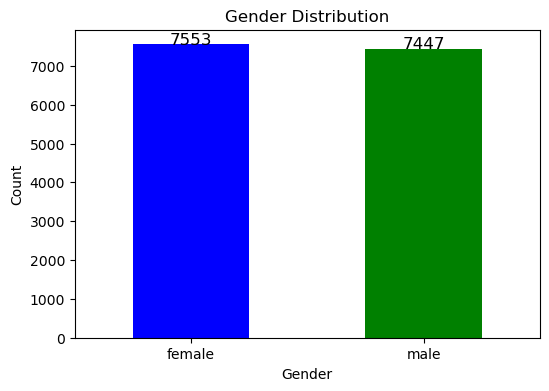

In [10]:
# Count occurrences of each gender
gender_counts = df['Gender'].value_counts()

# Create bar chart
plt.figure(figsize=(6,4))
ax = gender_counts.plot(kind='bar', color=['blue', 'green'])
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)


for i, value in enumerate(gender_counts):
    plt.text(i, value + 1, str(value), ha='center', fontsize=12)

plt.show()

In [12]:
#balanced gender distribution

In [14]:
# Function to assign generation category
def assign_generation(Age):
    if Age < 11:
        return 'Generation Alpha'
    elif Age < 27:
        return 'Generation Z'
    elif Age < 43:
        return 'Millennials'
    elif Age < 58:
        return 'Generation X'
    elif Age < 76:
        return 'Baby Boomers'
    else:
        return 'Silent Generation'

# Apply function to create a new column
df["Generation"] = df["Age"].apply(assign_generation)

df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,Generation
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0,Baby Boomers
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0,Generation Z
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0,Baby Boomers
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0,Millennials
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0,Millennials


In [16]:
#Average duration and calories by gender and generation
avg_dur_cal = df.groupby(["Generation", "Gender"])[["Duration", "Calories","Weight"]].mean().reset_index()
avg_dur_cal

,Generation,Gender,Duration,Calories,Weight
0,Baby Boomers,female,15.821308,96.609575,64.634525
1,Baby Boomers,male,15.785566,111.131159,88.553088
2,Generation X,female,15.551321,90.181315,63.966195
3,Generation X,male,15.310006,94.471455,87.701657
4,Generation Z,female,15.293103,81.419951,61.772167
5,Generation Z,male,15.641427,75.485607,84.701502
6,Millennials,female,15.408307,85.290361,62.803683
7,Millennials,male,15.547857,84.016820,86.263516
8,Silent Generation,female,15.599251,97.138577,65.142322
9,Silent Generation,male,15.482270,116.393617,89.953901


In [18]:
# Calculate BMI (Body Mass Index) using formula: weight (kg) / height (m)^2
df["BMI"] = df["Weight"] / (df["Height"] / 100) ** 2

# Define BMI segmentation categories
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif 18.5 <= bmi < 24.9:
        return "Normal weight"
    elif 25.0 <= bmi < 29.9:
        return "Overweight"
    else:
        return "Obese"

# Apply segmentation
df["Weight_Category"] = df["BMI"].apply(bmi_category)
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,Generation,BMI,Weight_Category
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0,Baby Boomers,26.038781,Overweight
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0,Generation Z,21.773842,Normal weight
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0,Baby Boomers,24.655910,Normal weight
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0,Millennials,22.159109,Normal weight
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0,Millennials,24.456063,Normal weight


In [20]:
# Count occurrences of each Weight_Category
weight_category_counts = df["Weight_Category"].value_counts()

# Calculate ratio considering the entire dataframe
weight_category_ratio = (weight_category_counts / len(df)) * 100  # Convert to percentage
weight_category_ratio

Weight_Category
Normal weight    62.326667
Overweight       34.720000
Obese             2.953333
Name: count, dtype: float64

In [22]:
# Creating the pivot table
pivot_table = df.pivot_table(
    values=["Duration", "Heart_Rate", "Body_Temp"], 
    index="Weight_Category",
    aggfunc="mean"
)

# Display the pivot table
pivot_table

,Body_Temp,Duration,Heart_Rate
Weight_Category,,,
Normal weight,40.021371,15.499840,95.439191
Obese,39.999323,15.320542,95.455982
Overweight,40.035004,15.603687,95.666283


In [24]:
# Count occurrences of each Weight_Category per Generation
pivot_table = df.pivot_table(
    values="User_ID", 
    index="Generation", 
    columns="Weight_Category", 
    aggfunc="count", 
    fill_value=0
)
# Sorting by 'Obese' count in descending order
pivot_table = pivot_table.sort_values(by="Obese", ascending=False)

# Display the pivot table
pivot_table

Weight_Category,Normal weight,Obese,Overweight
Generation,,,
Millennials,3346,140,1563
Baby Boomers,1478,100,1346
Generation X,1902,99,1255
Generation Z,2393,81,748
Silent Generation,230,23,296


In [26]:
# Calculating the ratio in percentage
total_users = df["User_ID"].count()
pivot_table_percentage = (pivot_table / total_users) * 100  # Convert to percentage
pivot_table_percentage

Weight_Category,Normal weight,Obese,Overweight
Generation,,,
Millennials,22.306667,0.933333,10.420000
Baby Boomers,9.853333,0.666667,8.973333
Generation X,12.680000,0.660000,8.366667
Generation Z,15.953333,0.540000,4.986667
Silent Generation,1.533333,0.153333,1.973333


In [28]:
df.describe()

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,BMI
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533,24.344900
std,2.872851e+06,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978,1.558784
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000,19.227688
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000,23.243408
50%,1.499728e+07,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000,24.376731
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000,25.492722
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000,29.069767


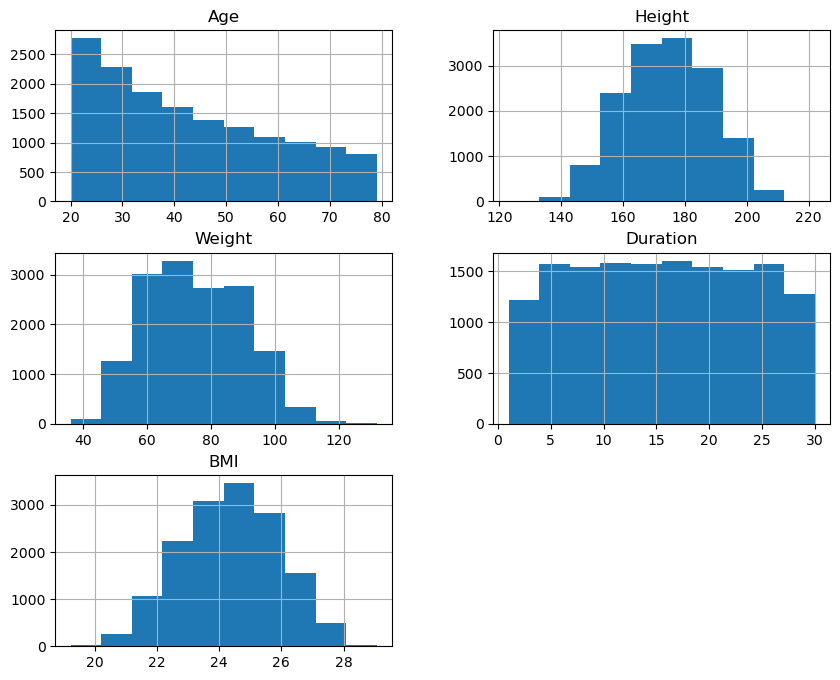

In [30]:
df[["Age", "Height", "Weight", "Duration", "BMI"]].hist(figsize=(10,8))  # Histogram visualization
plt.show()


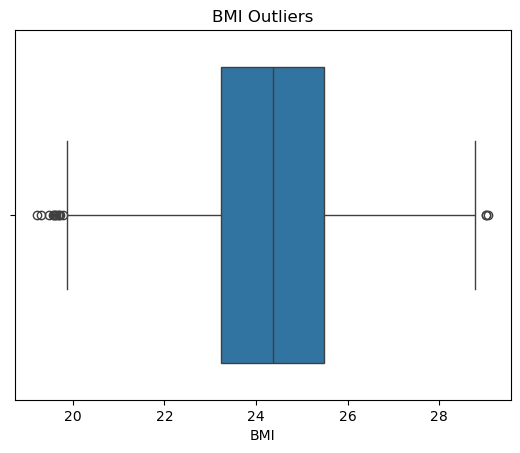

In [32]:
#checking outliers BMI

sns.boxplot(x=df["BMI"])  # Checking for extreme values
plt.title("BMI Outliers")
plt.show()

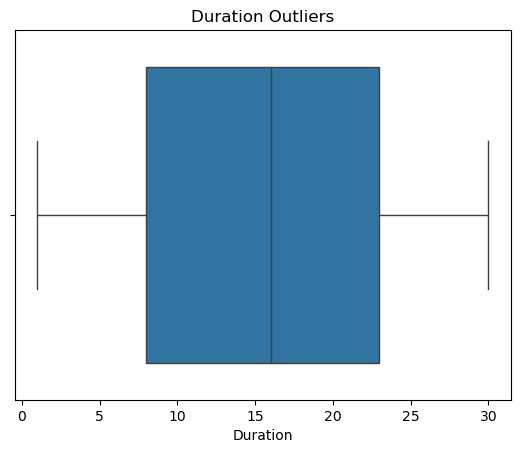

In [34]:
#checking outliers Duration
sns.boxplot(x=df["Duration"])  # Checking for extreme values
plt.title("Duration Outliers")
plt.show()

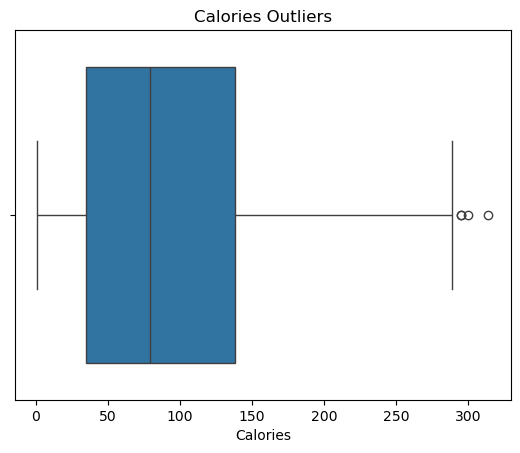

In [36]:
#checking outliers Calories
sns.boxplot(x=df["Calories"])  # Checking for extreme values
plt.title("Calories Outliers")
plt.show()

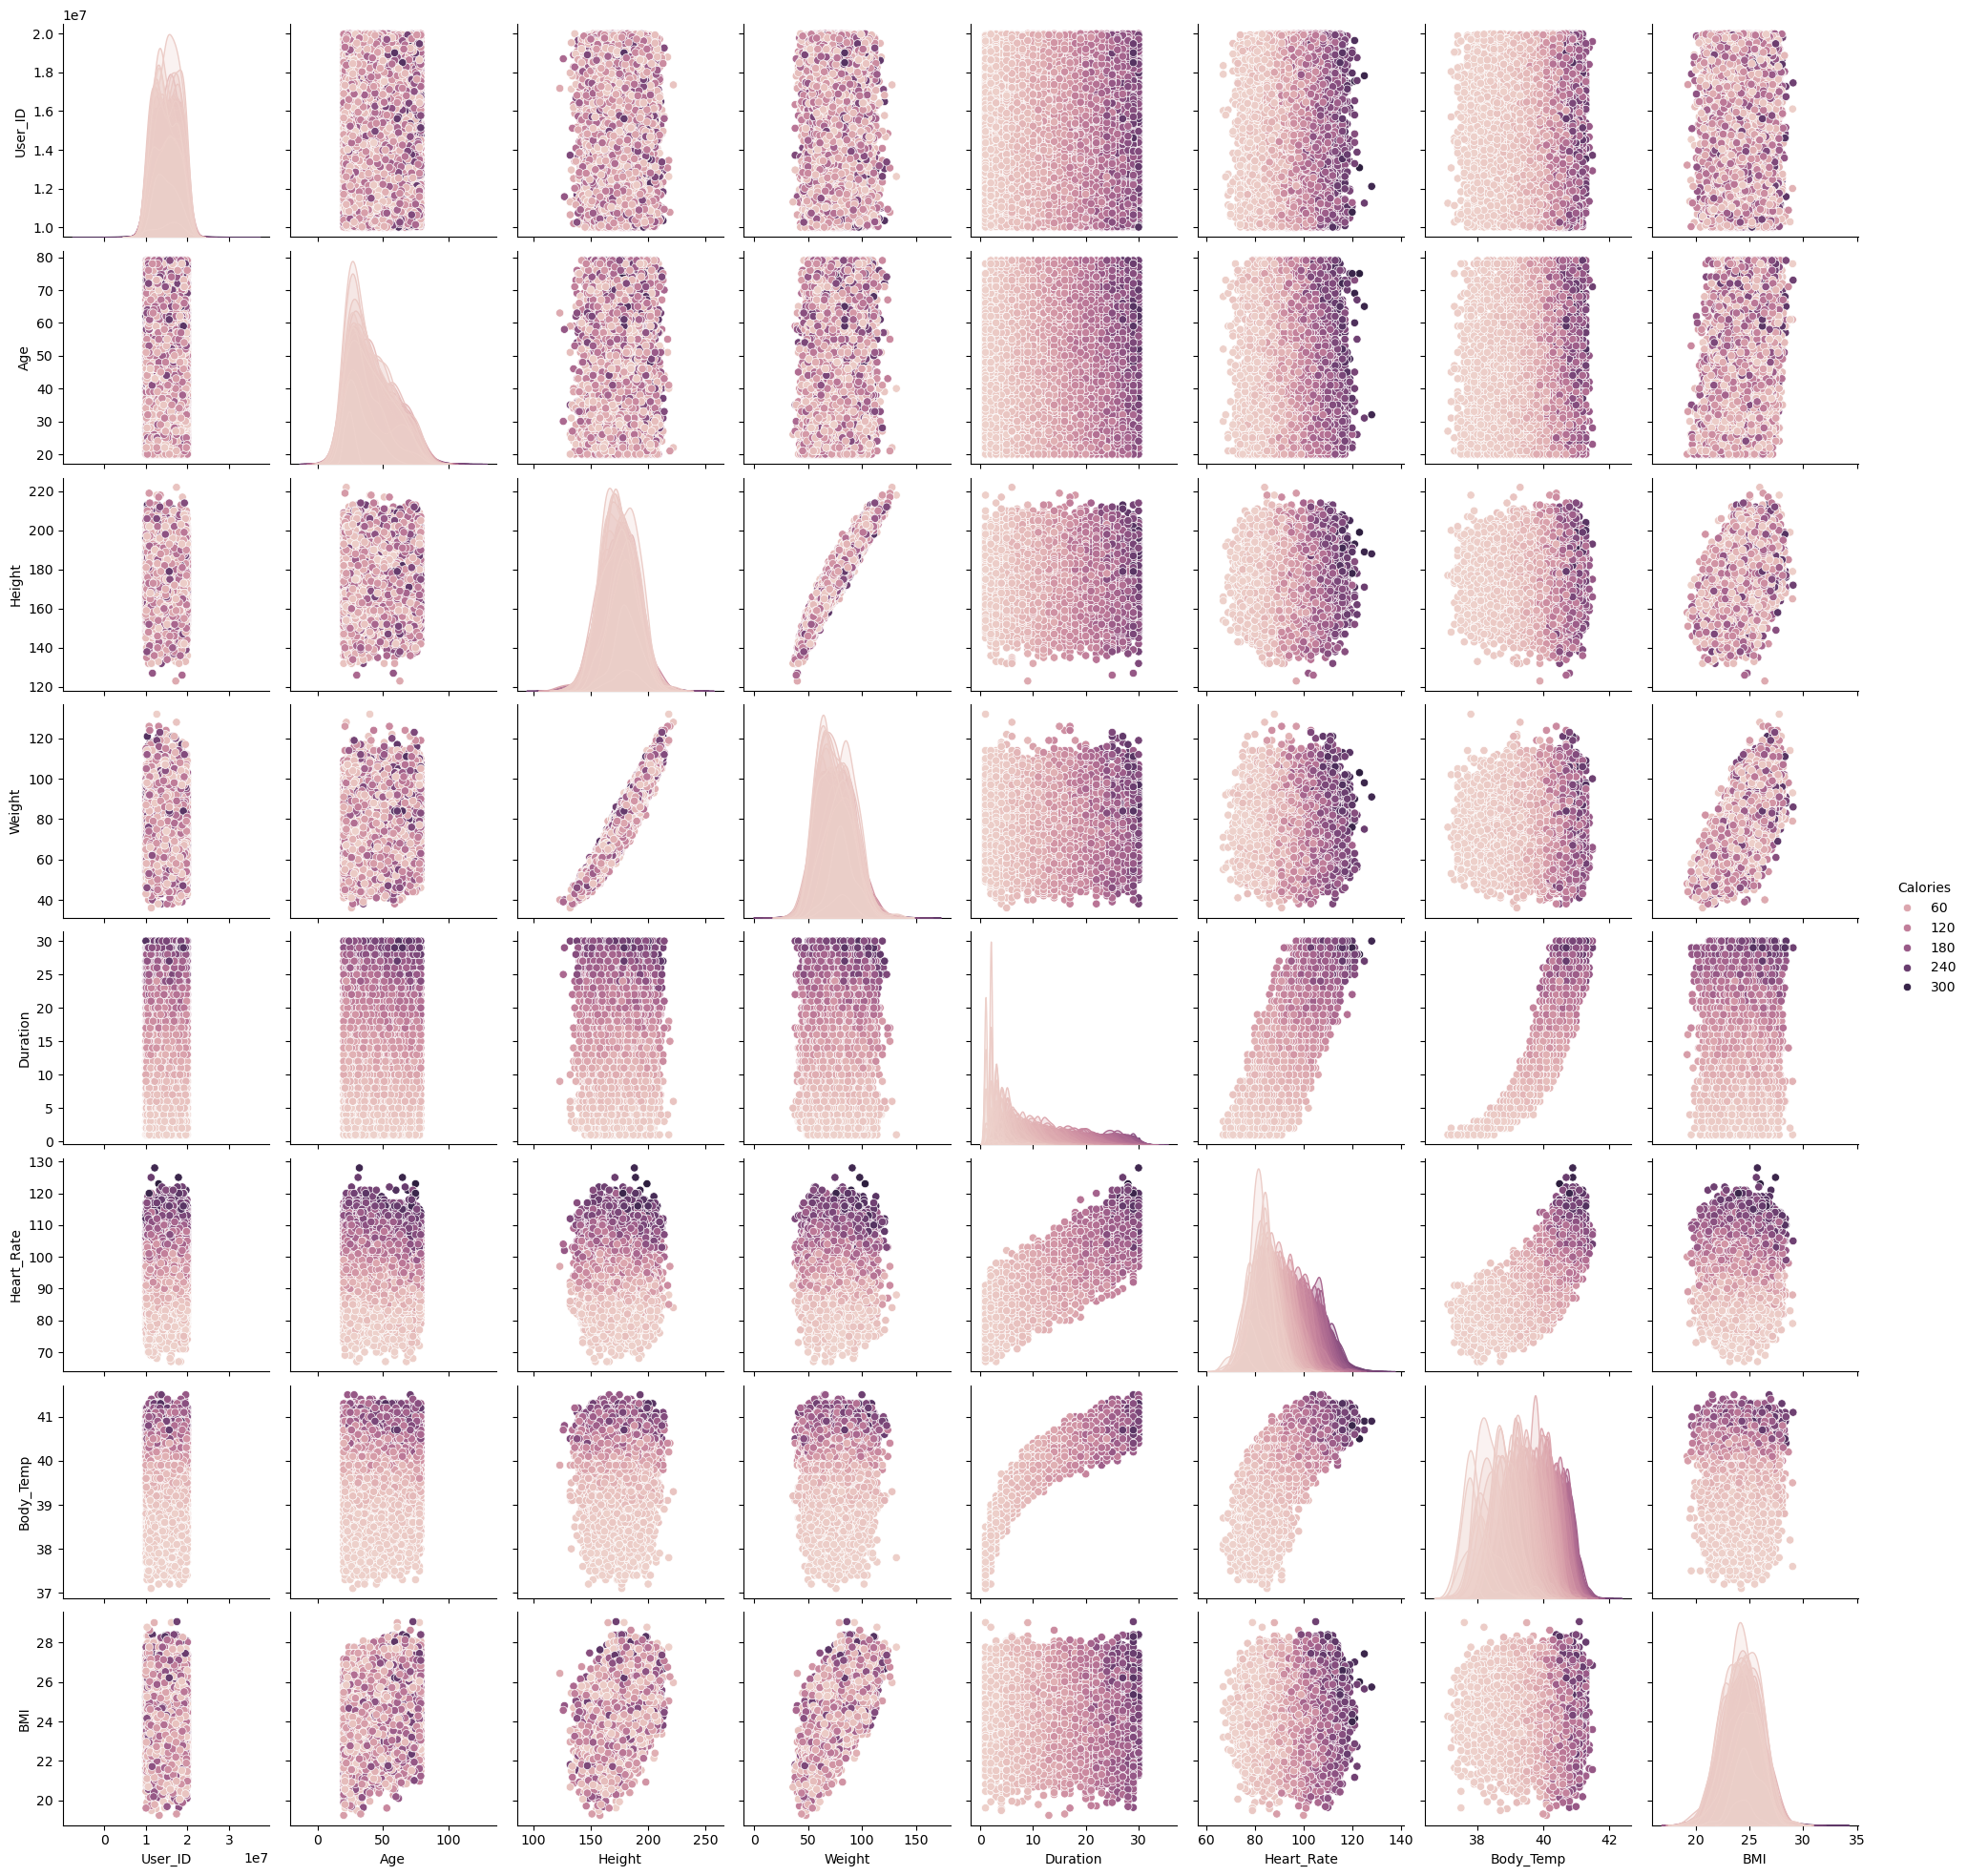

In [38]:
# Quick EDA with all variables
sns.pairplot(df, hue="Calories")
plt.show()

In [40]:
#LabelEncoder 0 = Female and 1 = Male 
label_encoder = LabelEncoder()
df["Gender"] = label_encoder.fit_transform(df["Gender"])

In [42]:
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,Generation,BMI,Weight_Category
0,14733363,1,68,190.0,94.0,29.0,105.0,40.8,231.0,Baby Boomers,26.038781,Overweight
1,14861698,0,20,166.0,60.0,14.0,94.0,40.3,66.0,Generation Z,21.773842,Normal weight
2,11179863,1,69,179.0,79.0,5.0,88.0,38.7,26.0,Baby Boomers,24.655910,Normal weight
3,16180408,0,34,179.0,71.0,13.0,100.0,40.5,71.0,Millennials,22.159109,Normal weight
4,17771927,0,27,154.0,58.0,10.0,81.0,39.8,35.0,Millennials,24.456063,Normal weight


In [44]:
#create a new dataframe without age and weight columns
new_columns = [
    'User_ID','Gender', 'Height', 'Duration', 'Heart_Rate', 'Body_Temp', 
    'Calories', 'Generation', 'BMI', 'Weight_Category'
]
df_new = df[new_columns]
df_new.head()

,User_ID,Gender,Height,Duration,Heart_Rate,Body_Temp,Calories,Generation,BMI,Weight_Category
0,14733363,1,190.0,29.0,105.0,40.8,231.0,Baby Boomers,26.038781,Overweight
1,14861698,0,166.0,14.0,94.0,40.3,66.0,Generation Z,21.773842,Normal weight
2,11179863,1,179.0,5.0,88.0,38.7,26.0,Baby Boomers,24.655910,Normal weight
3,16180408,0,179.0,13.0,100.0,40.5,71.0,Millennials,22.159109,Normal weight
4,17771927,0,154.0,10.0,81.0,39.8,35.0,Millennials,24.456063,Normal weight


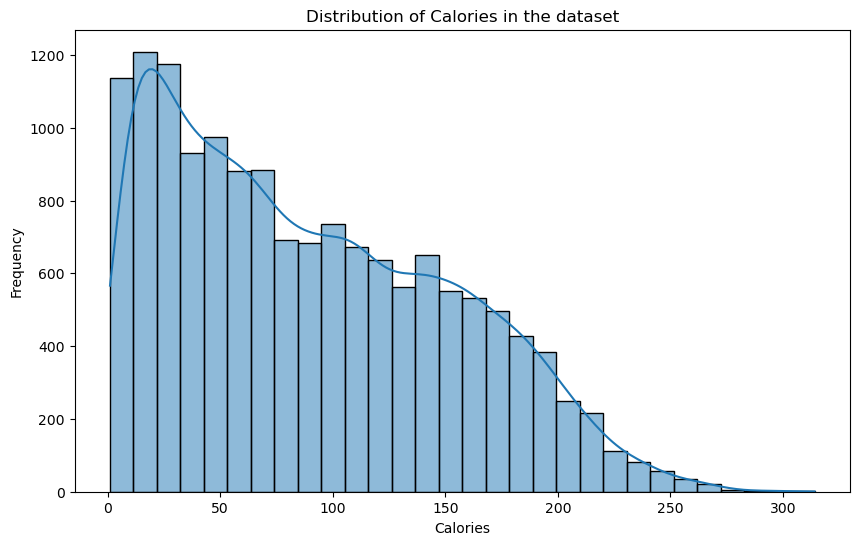

In [46]:
#Histogram with calories distribution in the dataset
plt.figure(figsize=(10,6))
sns.histplot(df_new["Calories"], bins=30, kde=True)
plt.title('Distribution of Calories in the dataset')
plt.xlabel('Calories')
plt.ylabel('Frequency')
plt.show()

In [48]:
#The histogram shows that most values are concentrated in the lower calorie ranges, peaking around 25 calories.
#Higher calorie values are less frequent.

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/3670891136.py:4: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=df_new['Duration'], y=df_new['Calories'], palette='coolwarm')


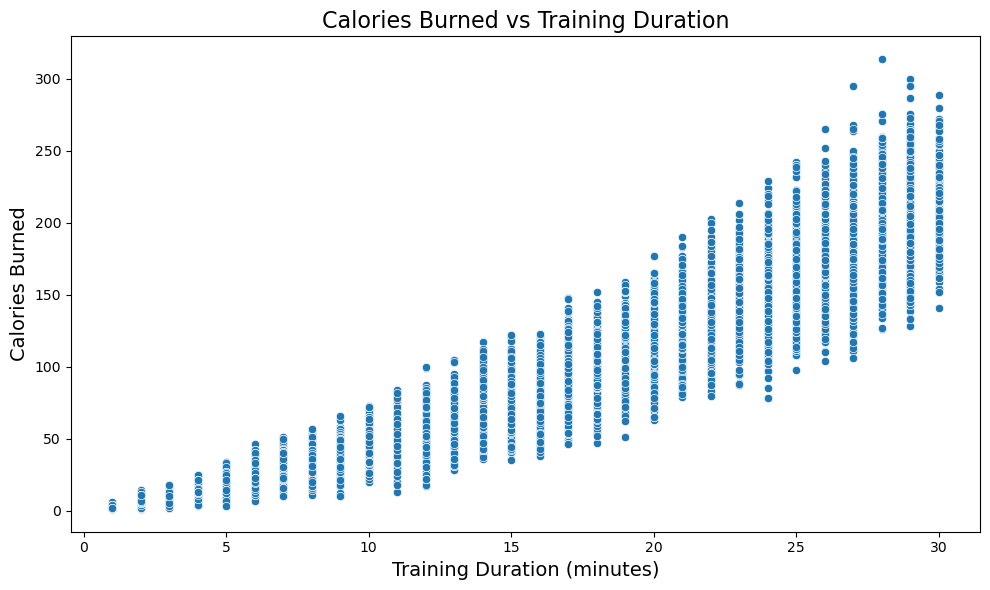

In [50]:
#Calories Burned vs Training Duration

plt.figure(figsize=(10,6))
sns.scatterplot(x=df_new['Duration'], y=df_new['Calories'], palette='coolwarm')

plt.title('Calories Burned vs Training Duration', fontsize=16)
plt.xlabel('Training Duration (minutes)', fontsize=14)
plt.ylabel('Calories Burned', fontsize=14)
plt.tight_layout()
plt.show()

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/3424653923.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=df_new['Duration'], y=df_new['Heart_Rate'], palette='coolwarm')


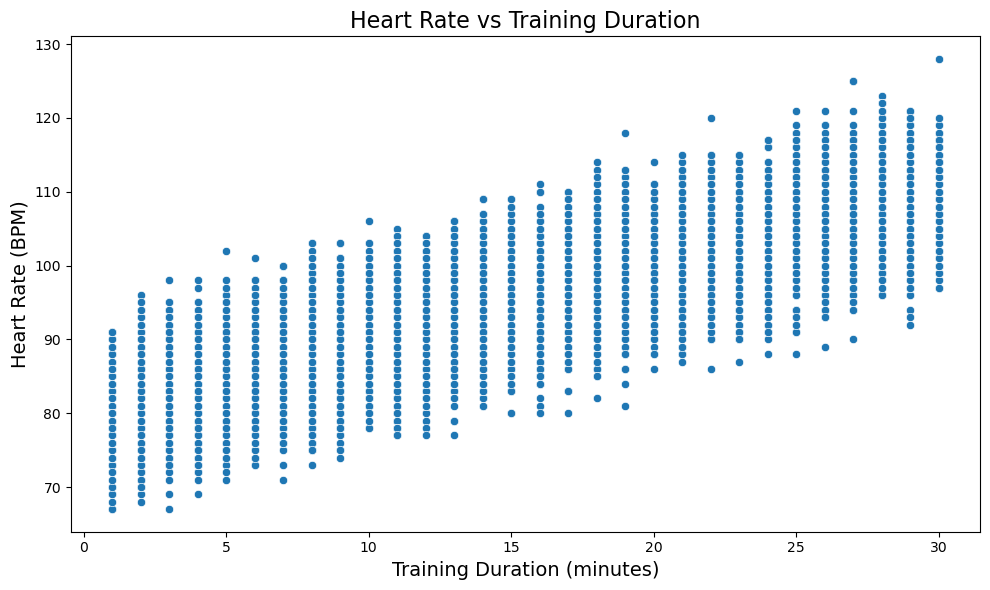

In [52]:
#Heart Rate vs Training Duration
plt.figure(figsize=(10,6))
sns.scatterplot(x=df_new['Duration'], y=df_new['Heart_Rate'], palette='coolwarm')

plt.title('Heart Rate vs Training Duration', fontsize=16)
plt.xlabel('Training Duration (minutes)', fontsize=14)
plt.ylabel('Heart Rate (BPM)', fontsize=14)

plt.tight_layout()
plt.show()

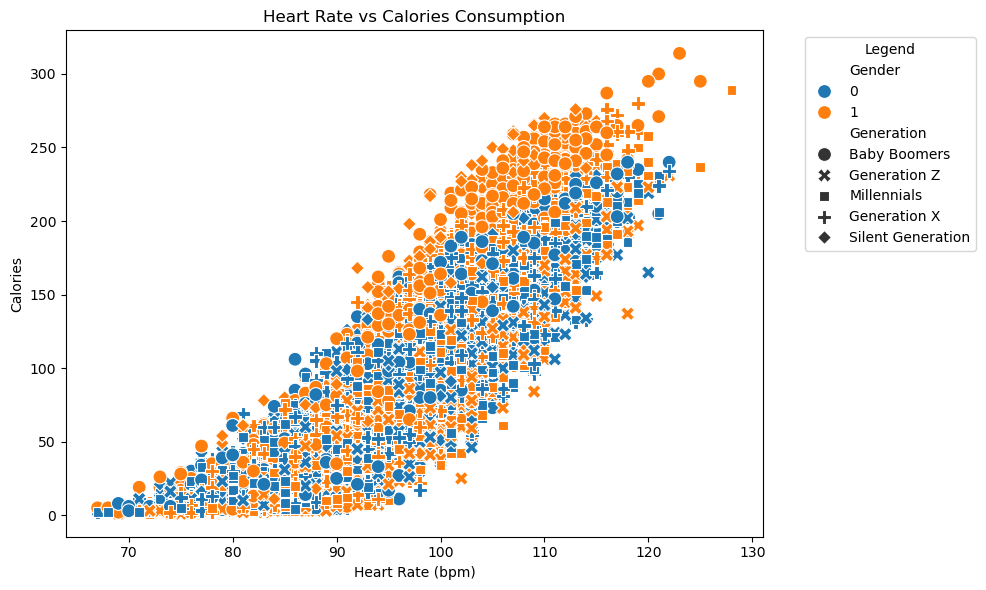

In [54]:
#Heart Rate vs Calories Consumption
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_new, x='Heart_Rate', y='Calories', hue='Gender', style='Generation', s=100)

plt.title('Heart Rate vs Calories Consumption')
plt.xlabel('Heart Rate (bpm)')
plt.ylabel('Calories')
plt.legend(title='Legend', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

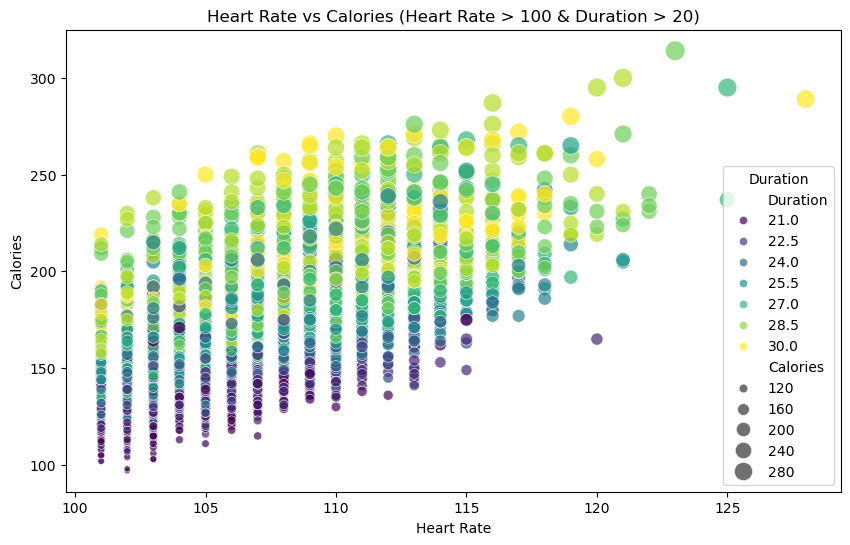

In [56]:
# Filter the DataFrame
filtered_df = df_new[(df_new['Heart_Rate'] > 100) & (df_new['Duration'] > 20)]

# Plot Heart Rate vs Calories with Calories as size
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=filtered_df,
    x='Heart_Rate',
    y='Calories',
    size='Calories',
    sizes=(20, 200),
    hue='Duration',
    palette='viridis',
    alpha=0.7
)

plt.title('Heart Rate vs Calories (Heart Rate > 100 & Duration > 20)')
plt.xlabel('Heart Rate')
plt.ylabel('Calories')
plt.legend(title='Duration')
plt.show()

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/258834793.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Generation', y='Duration', data=df_new, palette='Blues')  # Using a blue-toned palette


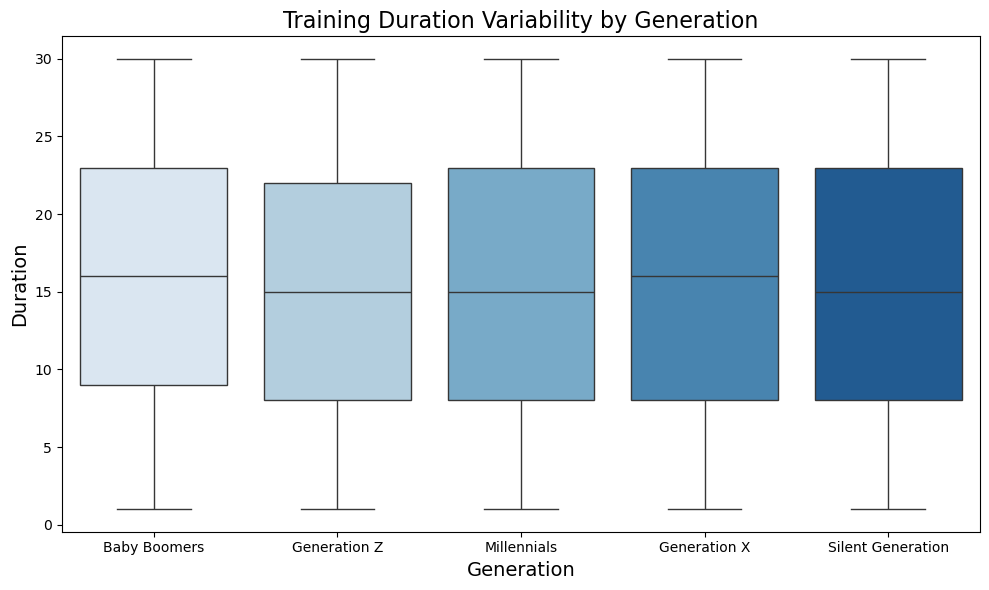

In [58]:
#Training Duration Variability by Generation
plt.figure(figsize=(10, 6))
sns.boxplot(x='Generation', y='Duration', data=df_new, palette='Blues')  # Using a blue-toned palette
plt.title('Training Duration Variability by Generation', fontsize=16)
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Duration', fontsize=14)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/3802540665.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Generation', y='Heart_Rate', data=df_new, palette='Reds')


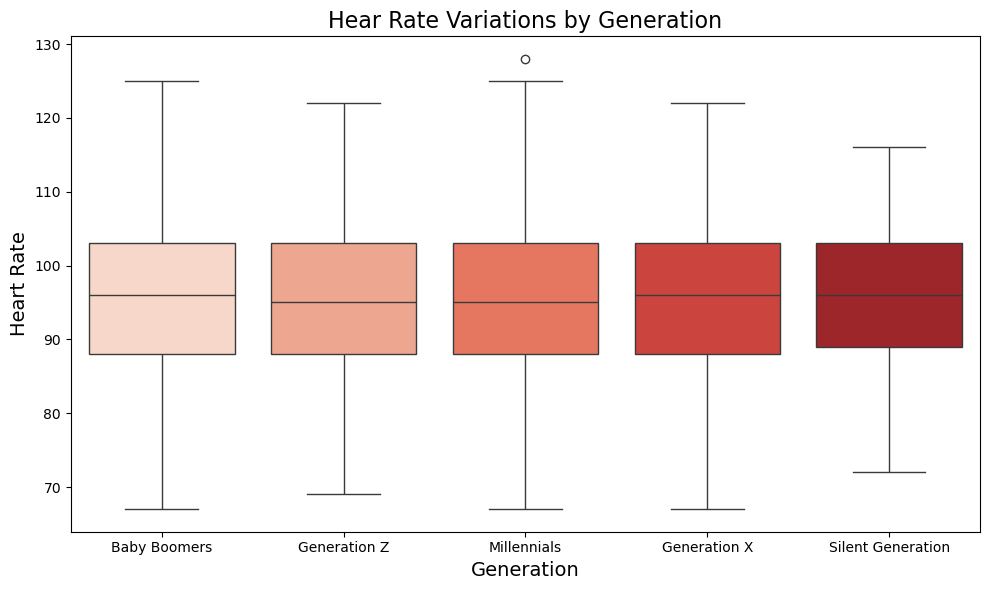

In [60]:
#Hear Rate Variations by Generation
plt.figure(figsize=(10, 6))
sns.boxplot(x='Generation', y='Heart_Rate', data=df_new, palette='Reds')
plt.title('Hear Rate Variations by Generation', fontsize=16)
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Heart Rate', fontsize=14)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/1734231484.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Generation', y='Calories', data=df_new, palette='Greens')


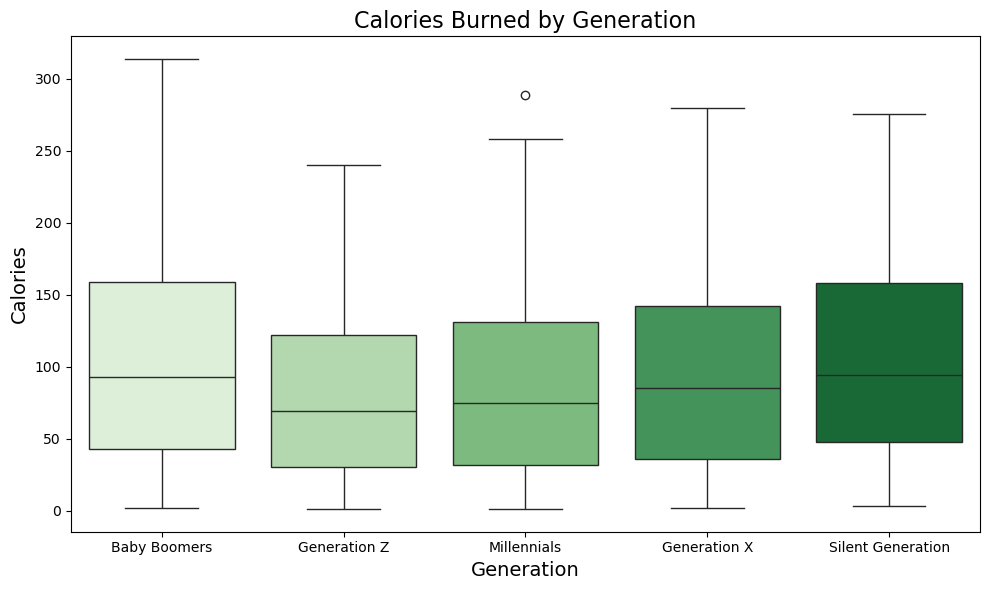

In [62]:
#Calories Burned by Generation
plt.figure(figsize=(10, 6))
sns.boxplot(x='Generation', y='Calories', data=df_new, palette='Greens')
plt.title('Calories Burned by Generation', fontsize=16)
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Calories', fontsize=14)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

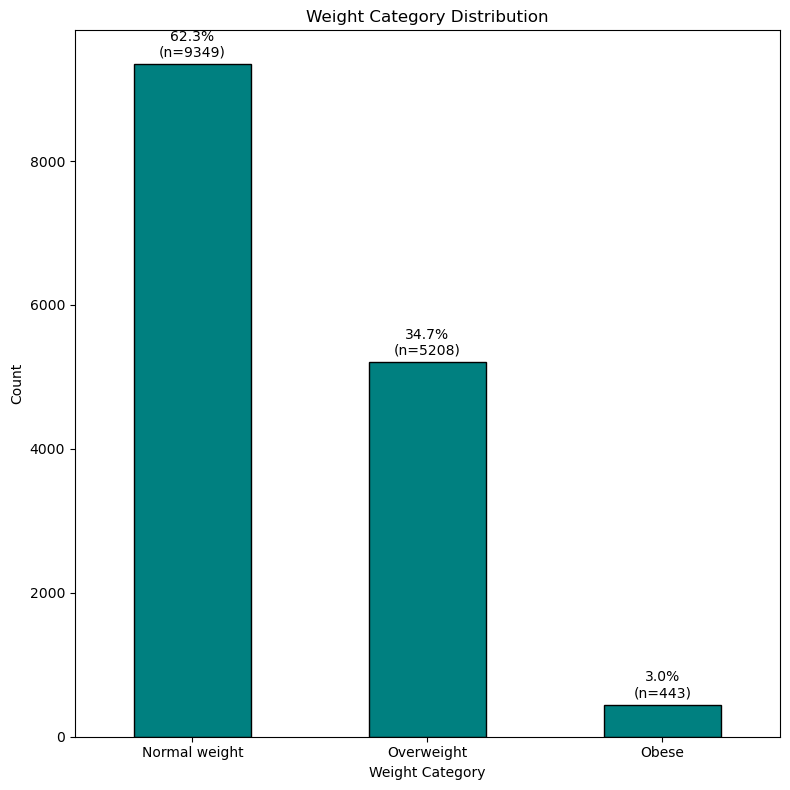

In [64]:
#Weight Category Distribution

# Create weight category counts
weight_counts = df_new["Weight_Category"].value_counts()

# Define teal color
teal_color = '#008080'  # Teal

# Create figure and axes
fig, ax = plt.subplots(figsize=(8,8))
bars = weight_counts.plot(kind='bar', ax=ax, color=teal_color, edgecolor='black')

# Calculate total count
total = weight_counts.sum()

# Add percentage and total count labels on top of each bar
for bar in bars.patches:
    height = bar.get_height()
    percentage = (height / total) * 100
    count = int(height)
    ax.annotate(f'{percentage:.1f}%\n(n={count})',
                (bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords='offset points',
                ha='center', va='bottom')

# Customize plot
plt.title('Weight Category Distribution')
plt.xlabel('Weight Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/373955377.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Female', 'Male'])


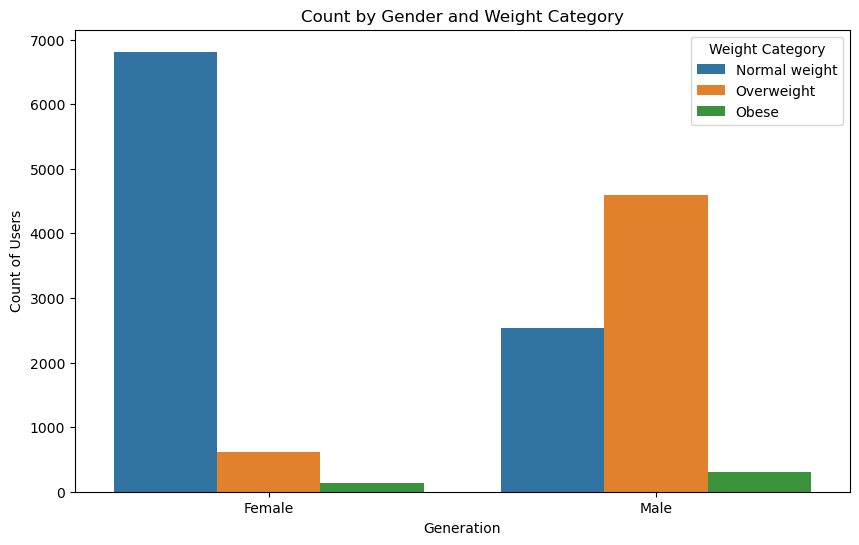

In [66]:
#Count by Gender and Weight Category
plt.figure(figsize=(10,6))
ax = sns.countplot(data=df_new, x='Gender', hue='Weight_Category')

plt.title('Count by Gender and Weight Category')
plt.xlabel('Generation')
plt.ylabel('Count of Users')

# Replace 0 and 1 with 'Female' and 'Male' on the X-axis
ax.set_xticklabels(['Female', 'Male'])

plt.legend(title='Weight Category')
plt.show()

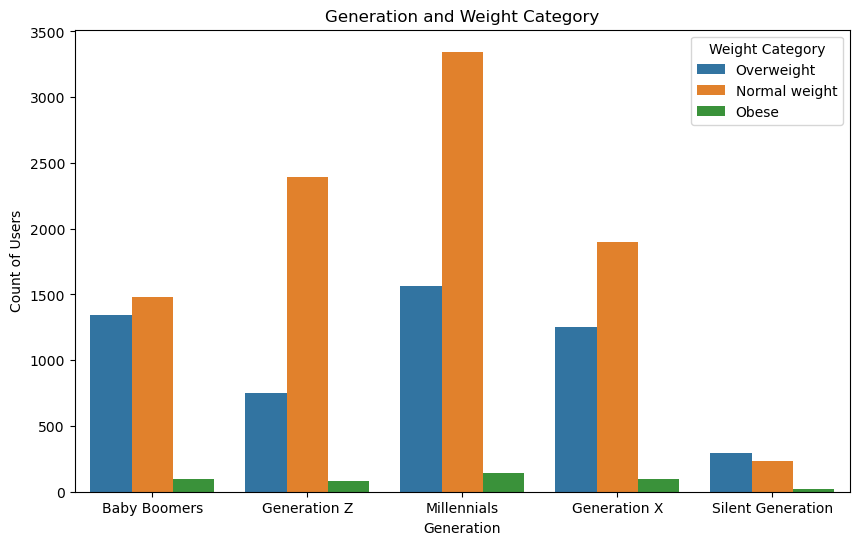

In [68]:
#Generation and Weight Category
plt.figure(figsize=(10,6))
sns.countplot(data=df_new, x='Generation', hue='Weight_Category')

plt.title('Generation and Weight Category')
plt.xlabel('Generation')
plt.ylabel('Count of Users')
plt.legend(title='Weight Category')
plt.show()

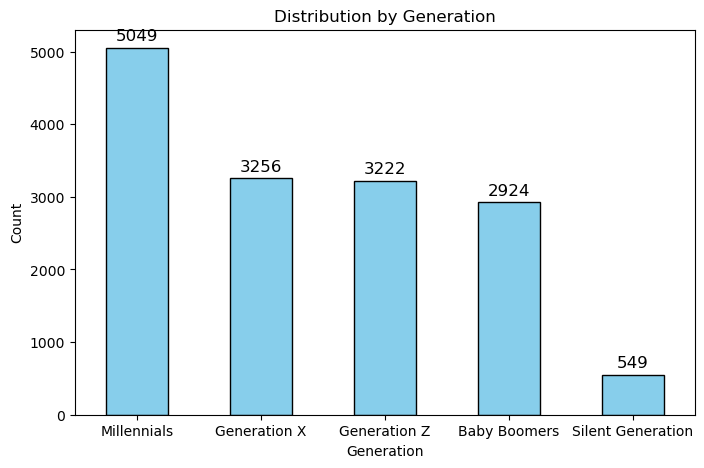

In [70]:
#Distribution by Generation

# Count occurrences by generation
generation_counts = df["Generation"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))
bars = generation_counts.plot(kind="bar", color="skyblue", edgecolor="black")

# Add labels above each bar
for bar in bars.containers:
    plt.bar_label(bar, label_type='edge', fontsize=12, padding=3)

# Add labels and title
plt.xlabel("Generation")
plt.ylabel("Count")
plt.title("Distribution by Generation")
plt.xticks(rotation=0)

# Show the plot
plt.show()



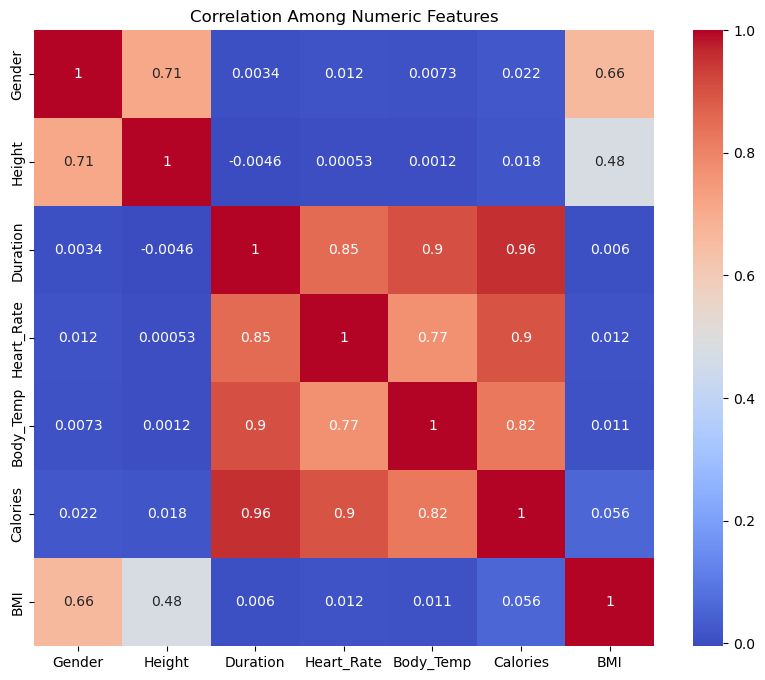

In [72]:
# Correlation Matrix

df_num = df_new.drop(columns=["User_ID", "Generation", "Weight_Category"])  # Keep Gender and other numeric features
# Correlation matrix
corr = df_num.corr()

# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Among Numeric Features')
plt.show()

In [74]:
#Correlation Coefficients:
#Values range from -1 to 1.
#1 indicates a perfect positive correlation.
#-1 indicates a perfect negative correlation.
#0 indicates no correlation.

#Key Observations:
#Calories & Duration  (0.96) → Longer exercise durations result in higher calorie expenditure.
#Calories & Heart (0.90) → A higher heart rate means greater calorie burning.
#Calories & Body Temperature (0.82) → Elevated body temperature indicates more energy expenditure.

In [76]:
dummies = pd.get_dummies(df[['Generation', 'Weight_Category']], drop_first=False)

df_with_dummies = pd.concat([df_new, dummies], axis=1)
df_with_dummies.head()

,User_ID,Gender,Height,Duration,Heart_Rate,Body_Temp,Calories,Generation,BMI,Weight_Category,Generation_Baby Boomers,Generation_Generation X,Generation_Generation Z,Generation_Millennials,Generation_Silent Generation,Weight_Category_Normal weight,Weight_Category_Obese,Weight_Category_Overweight
0,14733363,1,190.0,29.0,105.0,40.8,231.0,Baby Boomers,26.038781,Overweight,True,False,False,False,False,False,False,True
1,14861698,0,166.0,14.0,94.0,40.3,66.0,Generation Z,21.773842,Normal weight,False,False,True,False,False,True,False,False
2,11179863,1,179.0,5.0,88.0,38.7,26.0,Baby Boomers,24.655910,Normal weight,True,False,False,False,False,True,False,False
3,16180408,0,179.0,13.0,100.0,40.5,71.0,Millennials,22.159109,Normal weight,False,False,False,True,False,True,False,False
4,17771927,0,154.0,10.0,81.0,39.8,35.0,Millennials,24.456063,Normal weight,False,False,False,True,False,True,False,False


### Train Test Split

In [79]:
X = df_with_dummies.drop(columns = ["User_ID","Height","Body_Temp","Calories","Generation","Weight_Category","BMI"])
y= df_with_dummies["Calories"]

In [81]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

### Scalling

In [84]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [86]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [88]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)

In [90]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_train_scaled.head()

,Gender,Duration,Heart_Rate,Generation_Baby Boomers,Generation_Generation X,Generation_Generation Z,Generation_Millennials,Generation_Silent Generation,Weight_Category_Normal weight,Weight_Category_Obese,Weight_Category_Overweight
0,1.001501,-0.903038,-0.051801,-0.49596,-0.529408,-0.525149,-0.704457,5.187194,-1.288245,-0.172306,1.371299
1,-0.998501,-0.782820,-0.364380,-0.49596,1.888901,-0.525149,-0.704457,-0.192782,0.776250,-0.172306,-0.729236
2,-0.998501,0.178925,-0.781152,-0.49596,-0.529408,1.904222,-0.704457,-0.192782,0.776250,-0.172306,-0.729236
3,-0.998501,-0.782820,-1.093731,-0.49596,-0.529408,1.904222,-0.704457,-0.192782,0.776250,-0.172306,-0.729236
4,1.001501,-1.143475,-0.468573,-0.49596,-0.529408,-0.525149,1.419534,-0.192782,0.776250,-0.172306,-0.729236


In [92]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)
X_test_scaled.head()

,Gender,Duration,Heart_Rate,Generation_Baby Boomers,Generation_Generation X,Generation_Generation Z,Generation_Millennials,Generation_Silent Generation,Weight_Category_Normal weight,Weight_Category_Obese,Weight_Category_Overweight
0,-0.998501,-0.782820,-0.155994,-0.49596,-0.529408,-0.525149,1.419534,-0.192782,0.77625,-0.172306,-0.729236
1,1.001501,-1.143475,-1.406310,-0.49596,-0.529408,-0.525149,1.419534,-0.192782,0.77625,-0.172306,-0.729236
2,-0.998501,0.780015,-0.051801,-0.49596,-0.529408,-0.525149,1.419534,-0.192782,0.77625,-0.172306,-0.729236
3,1.001501,1.621542,1.615286,-0.49596,-0.529408,-0.525149,1.419534,-0.192782,0.77625,-0.172306,-0.729236
4,-0.998501,0.419361,0.781742,-0.49596,-0.529408,-0.525149,-0.704457,5.187194,0.77625,-0.172306,-0.729236


### KNN

In [95]:
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train_scaled, y_train)

KNeighborsRegressor(n_neighbors=10)

In [97]:
knn.score(X_test_scaled, y_test)

0.9912616911744885

In [99]:
#kNN model is performing very well, with an accuracy of 99.12%. 

### Ensemble Methods

#### Bagging

In [103]:
bagging_reg = BaggingRegressor(DecisionTreeRegressor(max_depth=6), n_estimators=100, max_samples = 1000)
bagging_reg.fit(X_train_scaled, y_train)

BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=6), max_samples=1000,
                 n_estimators=100)

In [105]:
pred_bagg = bagging_reg.predict(X_test_scaled)

print("MAE", mean_absolute_error(pred_bagg, y_test))
print("RMSE", mean_squared_error(pred_bagg, y_test, squared=False))
print("R2 score", bagging_reg.score(X_test_scaled, y_test))

MAE 5.77489688592337
RMSE 8.783227551637596
R2 score 0.9800071656827791


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


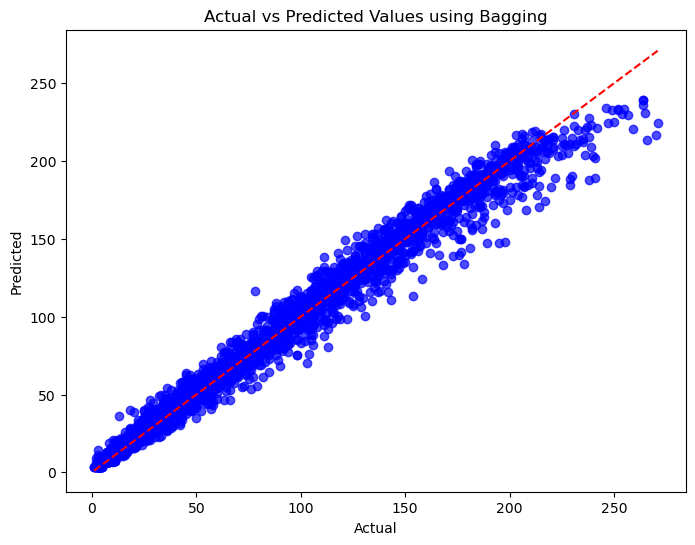

In [107]:
# Plot actual vs predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, pred_bagg, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Diagonal line

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Values using Bagging')
plt.show()

In [109]:
#this plot suggests that the bagging model performs well, as most points are closely aligned with the ideal prediction line

#### AdaBoost

In [112]:
ada_reg = AdaBoostRegressor(DecisionTreeRegressor(max_depth=20),n_estimators=100)
ada_reg.fit(X_train_scaled, y_train)

AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=20),
                  n_estimators=100)

In [113]:
pred_ada = ada_reg.predict(X_test_scaled)

print("MAE", mean_absolute_error(pred_ada, y_test))
print("RMSE", mean_squared_error(pred_ada, y_test, squared=False))
print("R2 score", ada_reg.score(X_test_scaled, y_test))

MAE 3.4855917090906776
RMSE 4.98447248344185
R2 score 0.9935612063978008


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


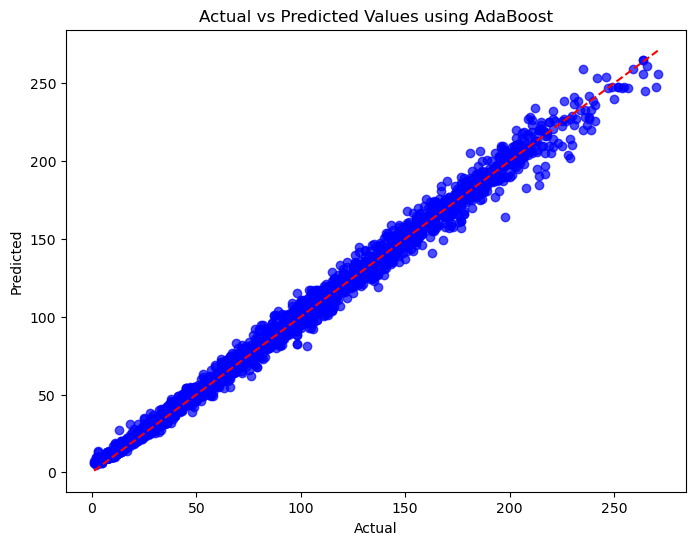

In [116]:
# Plot actual vs predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, pred_ada, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Diagonal line

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Values using AdaBoost')
plt.show()

#### RandomForest

In [119]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=20)
rf_model.fit(X_train_scaled, y_train)

RandomForestRegressor(random_state=20)

In [120]:
pred_rf = rf_model.predict(X_test_scaled)

print("MAE", mean_absolute_error(pred_rf, y_test))
print("RMSE", mean_squared_error(pred_rf, y_test, squared=False))
print("R2 score", rf_model.score(X_test_scaled, y_test))

MAE 3.133121963063711
RMSE 4.78063268123061
R2 score 0.9940770665859293


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [123]:
# #Model Evaluation Metrics:**

## MAE (Mean Absolute Error): 3.13
## Meaning: On average, the predicted values differ from the actual values by about 3.13 units.
## Interpretation: The average prediction error is approximately 3 units, which indicates fairly accurate predictions relative to the target variable's scale.

## RMSE (Root Mean Squared Error): 4.78
## Meaning: The typical deviation between predicted and actual values is about 4.78 units.
## Interpretation: Slightly higher than MAE, reflecting the model's error magnitude; still suggesting good performance.

## R² (Coefficient of Determination): 0.994
## Meaning: Approximately 99.41% of the variance in actual target values is explained by the model.
## Interpretation: The model fits the data very well, with predictions closely aligning with true values.

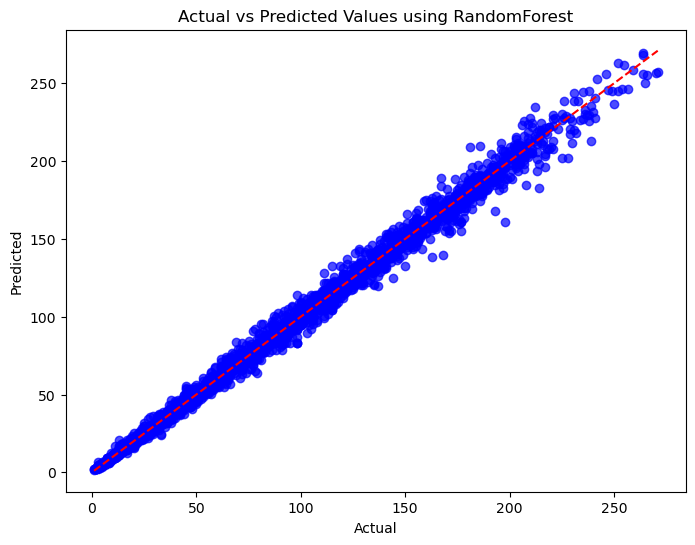

In [125]:
# Plot actual vs predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, pred_rf, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Diagonal line

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Values using RandomForest')
plt.show()

In [127]:
#Feature Importance for RandomForest
features = X_train_scaled.columns
importances = rf_model.feature_importances_

# Confirm the dimensions match
print("Number of features during training:", len(features))
print("Number of importance scores:", len(importances))
assert len(features) == len(importances), "Mismatch in feature count"

# Create a DataFrame or Series with correct feature names
feat_importance_df = pd.Series(importances, index=features).sort_values(ascending=False)
print(feat_importance_df)

Number of features during training: 11
Number of importance scores: 11
Duration                         0.916441
Heart_Rate                       0.050443
Generation_Baby Boomers          0.009694
Gender                           0.007692
Generation_Generation Z          0.004322
Generation_Silent Generation     0.003288
Generation_Generation X          0.003205
Generation_Millennials           0.003115
Weight_Category_Normal weight    0.001010
Weight_Category_Overweight       0.000696
Weight_Category_Obese            0.000093
dtype: float64


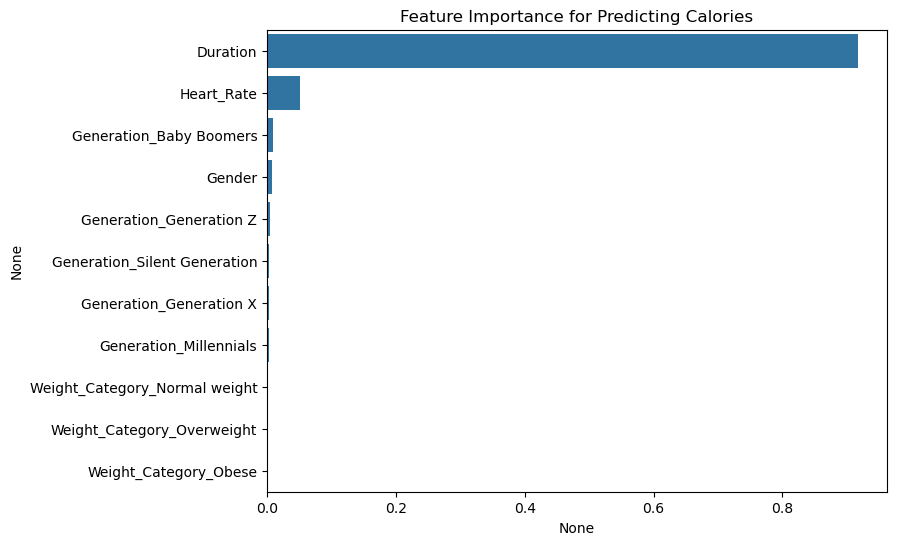

In [129]:
# Plot feature importance
plt.figure(figsize=(8,6))
sns.barplot(x=feat_importance_df, y=feat_importance_df.index)
plt.title('Feature Importance for Predicting Calories')
plt.show()

### GradientBoosting

In [132]:
gb_reg = GradientBoostingRegressor(max_depth=6, n_estimators=100)
gb_reg.fit(X_train_scaled, y_train)

GradientBoostingRegressor(max_depth=6)

In [133]:
pred_gb = gb_reg.predict(X_test_scaled)
print("MAE", mean_absolute_error(pred_gb, y_test))
print("RMSE", mean_squared_error(pred_gb, y_test, squared=False))
print("R2 score", gb_reg.score(X_test_scaled, y_test))

MAE 2.8133177823123225
RMSE 4.216096451059446
R2 score 0.9953933292486394


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


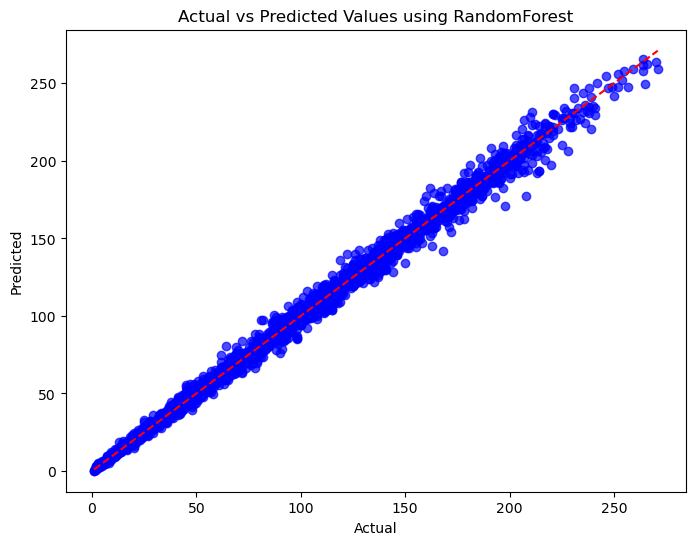

In [136]:
# Plot actual vs predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, pred_gb, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Diagonal line

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Values using RandomForest')
plt.show()

### Evaluate the different models

/var/folders/4g/4yj9rs3x2mxd3r_wz6p0pv080000gn/T/ipykernel_3950/425678989.py:33: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame.from_dict({'Model': [name], 'Dataset': ['Train'], 'RMSE': [rmse_train], 'R2': [r2_train]})], ignore_index=True)


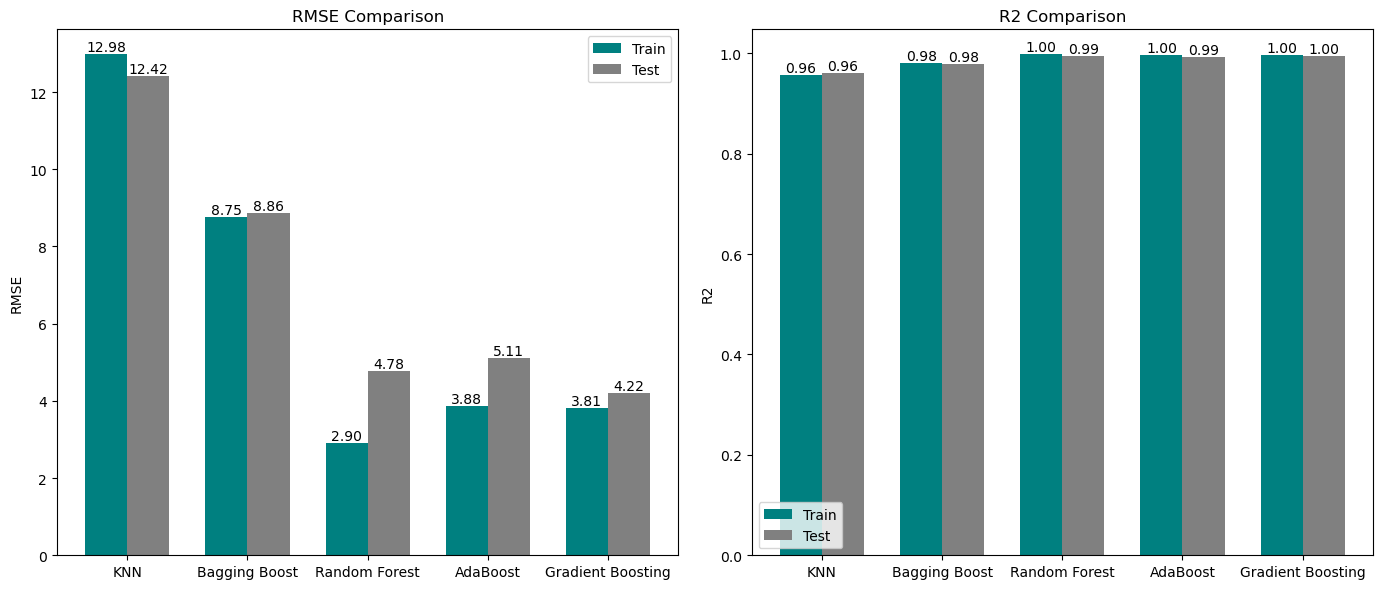

In [139]:
# Define custom colors
teal_color = '#008080'  # Teal for Train set
gray_color = '#808080'  # Gray for Test set


# Define models to evaluate
models = {
    'KNN': LinearRegression(),
    'Bagging Boost': BaggingRegressor(DecisionTreeRegressor(max_depth=6), n_estimators=100, max_samples = 1000),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=20),
    'AdaBoost': AdaBoostRegressor(DecisionTreeRegressor(max_depth=20),n_estimators=100),
    'Gradient Boosting': GradientBoostingRegressor(max_depth=6, n_estimators=100)
}

# Initialize a DataFrame to store results
results = pd.DataFrame(columns=['Model', 'Dataset', 'RMSE', 'R2'])

# Evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    # Predict on training data
    y_train_pred = model.predict(X_train_scaled)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    r2_train = r2_score(y_train, y_train_pred)
    
    # Predict on testing data
    y_test_pred = model.predict(X_test_scaled)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
    r2_test = r2_score(y_test, y_test_pred)
    
    # Append results to the DataFrame
    results = pd.concat([results, pd.DataFrame.from_dict({'Model': [name], 'Dataset': ['Train'], 'RMSE': [rmse_train], 'R2': [r2_train]})], ignore_index=True)
    results = pd.concat([results, pd.DataFrame.from_dict({'Model': [name], 'Dataset': ['Test'], 'RMSE': [rmse_test], 'R2': [r2_test]})], ignore_index=True)

# Define models and metrics
models = results['Model'].unique()
metrics = ['RMSE', 'R2']
datasets = ['Train', 'Test']
x = np.arange(len(models))  # the label locations
width = 0.35  # the width of the bars

# Create subplots for RMSE and R²
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for idx, metric in enumerate(metrics):
    ax = axes[idx]
    
    # Extract metric values for Train and Test
    train_values = results[results['Dataset'] == 'Train'][metric].values
    test_values = results[results['Dataset'] == 'Test'][metric].values
    
    # Plot bars side by side
    bars_train = ax.bar(x - width/2, train_values, width, label='Train', color=teal_color)
    bars_test = ax.bar(x + width/2, test_values, width, label='Test', color=gray_color)
    
    # Add values above bars
    for bar in bars_train:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{bar.get_height():.2f}', 
                ha='center', va='bottom', fontsize=10)

    for bar in bars_test:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{bar.get_height():.2f}', 
                ha='center', va='bottom', fontsize=10)

    # Set titles and labels
    ax.set_title(f'{metric} Comparison')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=0)
    ax.set_ylabel(metric)
    ax.legend()

plt.tight_layout()
plt.show()

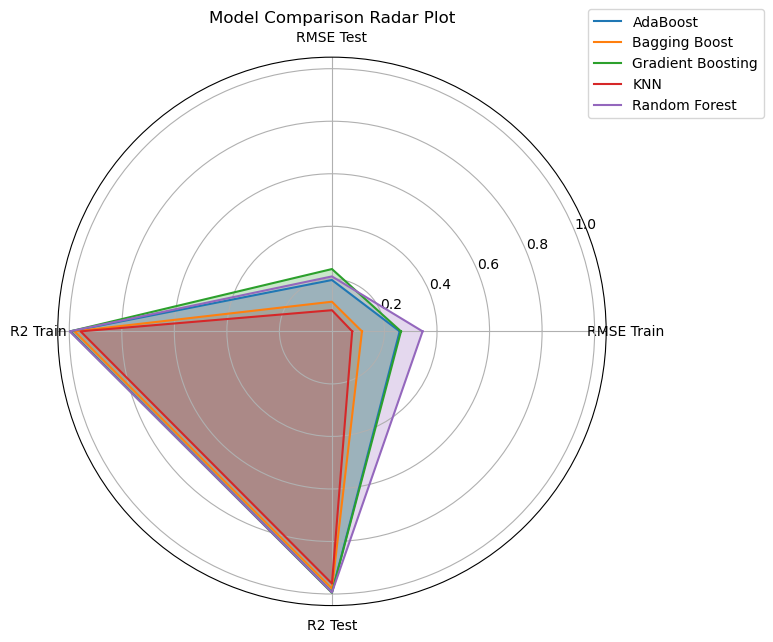

In [141]:
# Assume 'results' DataFrame exists with 'Model', 'Dataset', 'RMSE', 'R2' columns

# Pivot data for easier access
metrics_data = results.pivot(index='Model', columns='Dataset', values=['RMSE', 'R2'])

# Convert to a list for each model containing 4 metrics: RMSE Train, RMSE Test, R2 Train, R2 Test
# For consistency, invert RMSE for better visualization
metrics_data['RMSE'] = 1 / metrics_data['RMSE']

# Get list of models
models = list(metrics_data.index)

# Number of metrics per model
num_metrics = 4  # RMSE Train, RMSE Test, R2 Train, R2 Test
angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()

# Prepare data for radar plot
values = []

for model in models:
    rmse_train = metrics_data.loc[model, ('RMSE', 'Train')]
    rmse_test = metrics_data.loc[model, ('RMSE', 'Test')]
    r2_train = metrics_data.loc[model, ('R2', 'Train')]
    r2_test = metrics_data.loc[model, ('R2', 'Test')]
    # Create a list in the same order as angles
    model_metrics = [rmse_train, rmse_test, r2_train, r2_test]
    # Close the loop
    model_metrics += [model_metrics[0]]
    values.append(model_metrics)

# Plotting
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for i, model_values in enumerate(values):
    ax.plot(angles + [angles[0]], model_values, label=models[i])
    ax.fill(angles + [angles[0]], model_values, alpha=0.25)

# Add labels
labels = ['RMSE Train', 'RMSE Test', 'R2 Train', 'R2 Test']
ax.set_xticks(angles)
ax.set_xticklabels(labels)

ax.set_title('Model Comparison Radar Plot')
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()



### Hyperparameter Tuning

### Random Search

In [145]:
#Define hyperparameter distribution (use reasonable ranges to avoid too large a search space)
param_grid = {
    'n_estimators': [600, 800, 1000, 1200],
    'max_samples': [1800, 2500, 3000],
    'max_features': [0.75, 1.0, 1.5],
    'bootstrap': [True, False],  # Whether bootstrapping is used
    'estimator__max_depth': [8, 10, 12],  # Depth of base trees
    'estimator__min_samples_split': [2, 4, 6],  
    'estimator__min_samples_leaf': [1, 2, 4]  
}

In [147]:

# Apply RandomizedSearchCV
random_search = RandomizedSearchCV(bagging_reg, param_grid, n_iter=20, cv=5, n_jobs=-1, random_state=42, verbose=2)

In [149]:
# Fit the model
random_search.fit(X_train_scaled, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END bootstrap=False, estimator__max_depth=10, estimator__min_samples_leaf=4, estimator__min_samples_split=6, max_features=1.5, max_samples=1800, n_estimators=1000; total time=   0.0s
[CV] END bootstrap=False, estimator__max_depth=10, estimator__min_samples_leaf=1, estimator__min_samples_split=6, max_features=1.5, max_samples=3000, n_estimators=1000; total time=   0.0s
[CV] END bootstrap=False, estimator__max_depth=10, estimator__min_samples_leaf=1, estimator__min_samples_split=6, max_features=1.5, max_samples=3000, n_estimators=1000; total time=   0.0s
[CV] END bootstrap=False, estimator__max_depth=12, estimator__min_samples_leaf=1, estimator__min_samples_split=6, max_features=1.5, max_samples=1800, n_estimators=1000; total time=   0.0s
[CV] END bootstrap=False, estimator__max_depth=12, estimator__min_samples_leaf=1, estimator__min_samples_split=6, max_features=1.5, max_samples=1800, n_estimators=1000; total time=   0.0

/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
45 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py", line 66, in inner_f
    return f(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py", line 1466, in wrapper
    estimator._validate_params()
  File "/opt/anacond

RandomizedSearchCV(cv=5,
                   estimator=BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=6),
                                              max_samples=1000,
                                              n_estimators=100),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'estimator__max_depth': [8, 10, 12],
                                        'estimator__min_samples_leaf': [1, 2,
                                                                        4],
                                        'estimator__min_samples_split': [2, 4,
                                                                         6],
                                        'max_features': [0.75, 1.0, 1.5],
                                        'max_samples': [1800, 2500, 3000],
                                        'n_estimators': [600, 800, 1000, 1200]},
                   random_state=42, verbose=2)

In [151]:
# Get the best hyperparameters
random_search.best_params_

{'n_estimators': 1200,
 'max_samples': 3000,
 'max_features': 1.0,
 'estimator__min_samples_split': 4,
 'estimator__min_samples_leaf': 2,
 'estimator__max_depth': 10,
 'bootstrap': False}

In [153]:
# Get the best model
best_model = random_search.best_estimator_

In [155]:
# Evaluate the best model on the test set
best_pred_br = best_model.predict(X_test_scaled)

print("MAE", mean_absolute_error(best_pred_br, y_test))
print("RMSE", mean_squared_error(best_pred_br, y_test, squared=False))
print("R2 score", best_model.score(X_test_scaled, y_test))


MAE 3.347605650214494
RMSE 5.2776564812469005


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


R2 score 0.9927814771431052


### Compare Before vs After Tuning using Random Search

In [158]:
# Before tuning
print("Baseline Bagg Regressor:")
print("MAE", mean_absolute_error(pred_bagg, y_test))
print("RMSE", mean_squared_error(pred_bagg, y_test, squared=False))
print("R²:", bagging_reg.score(X_test_scaled, y_test))

# After tuning
print("\nTuned Bagg Regressor:")
print("MAE:", mean_absolute_error(y_test, best_pred_br))
print("RMSE:", mean_squared_error(y_test, best_pred_br, squared=False))
print("R²:", best_model.score(X_test_scaled, y_test))

Baseline Bagg Regressor:
MAE 5.77489688592337
RMSE 8.783227551637596
R²: 0.9800071656827791

Tuned Bagg Regressor:
MAE: 3.347605650214494
RMSE: 5.2776564812469005


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


R²: 0.9927814771431052


In [160]:
# Hyperparameter tuning  shows a significant improvement over the baseline model, indicating more precise predictions.

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


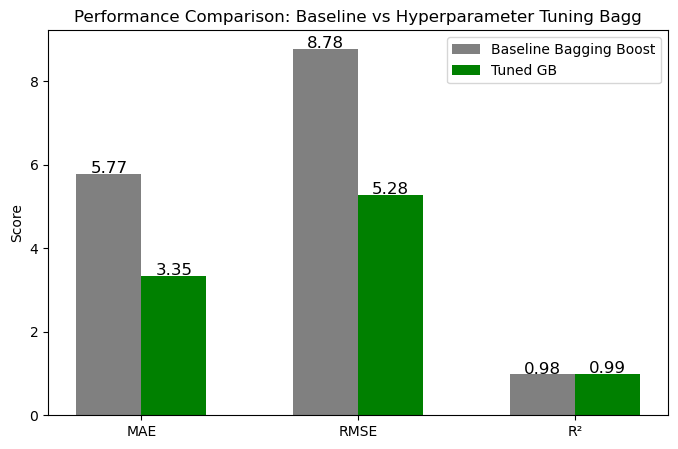

In [162]:

# Define metrics
metrics = ["MAE", "RMSE", "R²"]
baseline_values = [
    mean_absolute_error(pred_bagg, y_test),
    mean_squared_error(pred_bagg, y_test, squared=False),
    bagging_reg.score(X_test_scaled, y_test)
]
tuned_values = [
    mean_absolute_error(y_test, best_pred_br),
    mean_squared_error(y_test, best_pred_br, squared=False),
    best_model.score(X_test_scaled, y_test)
]

# Set position of bars
x = np.arange(len(metrics))
width = 0.3

# Create figure
plt.figure(figsize=(8, 5))
plt.bar(x - width/2, baseline_values, width, label="Baseline Bagging Boost", color="grey")
plt.bar(x + width/2, tuned_values, width, label="Tuned GB", color="Green")

# Add labels
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Performance Comparison: Baseline vs Hyperparameter Tuning Bagg")
plt.legend(loc="upper right", ncol=1)  # Horizontal legend

# Show values on bars
for i in range(len(metrics)):
    plt.text(i - width/2, baseline_values[i] + 0.02, f"{baseline_values[i]:.2f}", ha='center', fontsize=12)
    plt.text(i + width/2, tuned_values[i] + 0.02, f"{tuned_values[i]:.2f}", ha='center', fontsize=12)

# Show chart
plt.show()


### New dataframe with Estimated BPM

In [164]:
# Define data Estimated BPM
data = {
    "Generation": [
        "Generation Alpha", "Generation Z", "Millennials",
        "Generation X", "Baby Boomers", "Silent Generation"
    ],
    "Common Fitness Trends": [
        "Active play",
        "HIIT",
        "Endurance sports",
        "Functional fitness",
        "low-impact",
        "Gentle mobility"
    ],
    "Estimated BPM": [
        "90–140 bpm",  # Younger ages tend to have higher heart rates
        "134–190 bpm",
        "114–162 bpm",
        "95–133 bpm",
        "76–114 bpm",
        "60–100 bpm"
    ]
}
# Create DataFrame
df_bpm = pd.DataFrame(data)
# Display table
df_bpm

,Generation,Common Fitness Trends,Estimated BPM
0,Generation Alpha,Active play,90–140 bpm
1,Generation Z,HIIT,134–190 bpm
2,Millennials,Endurance sports,114–162 bpm
3,Generation X,Functional fitness,95–133 bpm
4,Baby Boomers,low-impact,76–114 bpm
5,Silent Generation,Gentle mobility,60–100 bpm


In [166]:
# Rename columns by replacing spaces with underscores
df_bpm.columns = df_bpm.columns.str.replace(' ', '_')

# Display the updated DataFrame
df_bpm


,Generation,Common_Fitness_Trends,Estimated_BPM
0,Generation Alpha,Active play,90–140 bpm
1,Generation Z,HIIT,134–190 bpm
2,Millennials,Endurance sports,114–162 bpm
3,Generation X,Functional fitness,95–133 bpm
4,Baby Boomers,low-impact,76–114 bpm
5,Silent Generation,Gentle mobility,60–100 bpm


In [168]:
df_bpm.to_csv('generation_fitness_bpm.csv', index=False)

In [170]:
df_bpm = pd.read_csv("/Users/verapinto/Desktop/Projects/ML_Project_3/generation_fitness_bpm.csv")
df_bpm

,Generation,Common_Fitness_Trends,Estimated_BPM
0,Generation Alpha,Active play,90–140 bpm
1,Generation Z,HIIT,134–190 bpm
2,Millennials,Endurance sports,114–162 bpm
3,Generation X,Functional fitness,95–133 bpm
4,Baby Boomers,low-impact,76–114 bpm
5,Silent Generation,Gentle mobility,60–100 bpm


In [172]:
# Remove ' bpm' from the column values
df_bpm['Estimated_BPM'] = df_bpm['Estimated_BPM'].str.replace(' bpm', '', regex=True)

# Split "Estimated BPM" into "Min BPM" and "Max BPM"
df_bpm[['Min_BPM', 'Max_BPM']] = df_bpm['Estimated_BPM'].str.split('–', expand=True)

# Convert BPM columns to integers
df_bpm['Min_BPM'] = df_bpm['Min_BPM'].astype(int)
df_bpm['Max_BPM'] = df_bpm['Max_BPM'].astype(int)

# Display DataFrame
df_bpm

,Generation,Common_Fitness_Trends,Estimated_BPM,Min_BPM,Max_BPM
0,Generation Alpha,Active play,90–140,90,140
1,Generation Z,HIIT,134–190,134,190
2,Millennials,Endurance sports,114–162,114,162
3,Generation X,Functional fitness,95–133,95,133
4,Baby Boomers,low-impact,76–114,76,114
5,Silent Generation,Gentle mobility,60–100,60,100


In [174]:
# Merge df_new with df_bpm based on Generation to add Recommended_Exercise, Min_BPM, and Max_BPM columns
df_bpm_new = df_new.merge(df_bpm[['Generation', 'Common_Fitness_Trends', 'Min_BPM', 'Max_BPM']], on='Generation', how='left')

# Rename columns for clarity
df_bpm_new.rename(columns={'Common_Fitness_Trends': 'Recommended_Exercise'}, inplace=True)

# Display updated DataFrame
df_bpm_new.head()


,User_ID,Gender,Height,Duration,Heart_Rate,Body_Temp,Calories,Generation,BMI,Weight_Category,Recommended_Exercise,Min_BPM,Max_BPM
0,14733363,1,190.0,29.0,105.0,40.8,231.0,Baby Boomers,26.038781,Overweight,low-impact,76,114
1,14861698,0,166.0,14.0,94.0,40.3,66.0,Generation Z,21.773842,Normal weight,HIIT,134,190
2,11179863,1,179.0,5.0,88.0,38.7,26.0,Baby Boomers,24.655910,Normal weight,low-impact,76,114
3,16180408,0,179.0,13.0,100.0,40.5,71.0,Millennials,22.159109,Normal weight,Endurance sports,114,162
4,17771927,0,154.0,10.0,81.0,39.8,35.0,Millennials,24.456063,Normal weight,Endurance sports,114,162


### Considering Max BPM

In [177]:
# Drop unnecessary columns first
df_cleaned = df_bpm_new.drop(columns=["User_ID", "Height", "Body_Temp", "Calories", "BMI", "Min_BPM", "Recommended_Exercise", "Heart_Rate"])
df_cleaned.head()

,Gender,Duration,Generation,Weight_Category,Max_BPM
0,1,29.0,Baby Boomers,Overweight,114
1,0,14.0,Generation Z,Normal weight,190
2,1,5.0,Baby Boomers,Normal weight,114
3,0,13.0,Millennials,Normal weight,162
4,0,10.0,Millennials,Normal weight,162


In [179]:
df_cleaned.rename(columns={'Max_BPM': 'Heart_Rate'}, inplace=True)

# Display updated DataFrame
df_cleaned.head()

,Gender,Duration,Generation,Weight_Category,Heart_Rate
0,1,29.0,Baby Boomers,Overweight,114
1,0,14.0,Generation Z,Normal weight,190
2,1,5.0,Baby Boomers,Normal weight,114
3,0,13.0,Millennials,Normal weight,162
4,0,10.0,Millennials,Normal weight,162


In [181]:

# Encode categorical variables (correct syntax for multiple columns)
dummies = pd.get_dummies(df_cleaned[['Generation', 'Weight_Category']], drop_first=False)

# Merge encoded variables into the DataFrame
df_final = pd.concat([df_cleaned, dummies], axis=1)

# Drop the original categorical columns now that they are encoded
df_final = df_final.drop(columns=['Generation', 'Weight_Category'])

# Display updated DataFrame
df_final.head()


,Gender,Duration,Heart_Rate,Generation_Baby Boomers,Generation_Generation X,Generation_Generation Z,Generation_Millennials,Generation_Silent Generation,Weight_Category_Normal weight,Weight_Category_Obese,Weight_Category_Overweight
0,1,29.0,114,True,False,False,False,False,False,False,True
1,0,14.0,190,False,False,True,False,False,True,False,False
2,1,5.0,114,True,False,False,False,False,True,False,False
3,0,13.0,162,False,False,False,True,False,True,False,False
4,0,10.0,162,False,False,False,True,False,True,False,False


In [183]:
df_final.columns

Index(['Gender', 'Duration', 'Heart_Rate', 'Generation_Baby Boomers',
       'Generation_Generation X', 'Generation_Generation Z',
       'Generation_Millennials', 'Generation_Silent Generation',
       'Weight_Category_Normal weight', 'Weight_Category_Obese',
       'Weight_Category_Overweight'],
      dtype='object')

In [185]:
# Create X_new with corrected data types
X_new = df_final

# Apply the same scaler you used before 
X_new_scaled = scaler.transform(X_new)

#Predict new calories burned using best model
df_final['Predicted_Calories'] = best_model.predict(X_new_scaled)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but BaggingRegressor was fitted with feature names
  warnings.warn(


In [187]:
df_final.head()

,Gender,Duration,Heart_Rate,Generation_Baby Boomers,Generation_Generation X,Generation_Generation Z,Generation_Millennials,Generation_Silent Generation,Weight_Category_Normal weight,Weight_Category_Obese,Weight_Category_Overweight,Predicted_Calories
0,1,29.0,114,True,False,False,False,False,False,False,True,259.954375
1,0,14.0,190,False,False,True,False,False,True,False,False,84.909145
2,1,5.0,114,True,False,False,False,False,True,False,False,28.264536
3,0,13.0,162,False,False,False,True,False,True,False,False,78.547178
4,0,10.0,162,False,False,False,True,False,True,False,False,55.966590


In [189]:
# Re-add User_ID from df_bpm_new before merging
df_final = df_bpm_new[['User_ID']].merge(df_final, how='left', left_index=True, right_index=True)

# Merge Predicted_Calories into df_bpm_new
df_bpm_new = df_bpm_new.merge(df_final[['User_ID', 'Predicted_Calories']], on='User_ID', how='left')

# Compare actual vs. predicted calories
df_bpm_new['Calories_Difference'] = df_bpm_new['Predicted_Calories'] - df_bpm_new['Calories']

# Display comparison
df_bpm_new[['User_ID','Generation','Weight_Category', 'Duration', 'Heart_Rate', 'Max_BPM', 'Calories', 'Predicted_Calories', 'Calories_Difference']].head()



,User_ID,Generation,Weight_Category,Duration,Heart_Rate,Max_BPM,Calories,Predicted_Calories,Calories_Difference
0,14733363,Baby Boomers,Overweight,29.0,105.0,114,231.0,259.954375,28.954375
1,14861698,Generation Z,Normal weight,14.0,94.0,190,66.0,84.909145,18.909145
2,11179863,Baby Boomers,Normal weight,5.0,88.0,114,26.0,28.264536,2.264536
3,16180408,Millennials,Normal weight,13.0,100.0,162,71.0,78.547178,7.547178
4,17771927,Millennials,Normal weight,10.0,81.0,162,35.0,55.966590,20.966590


In [191]:
# Add 'Comparison' column based on calorie difference
df_bpm_new['Comparison'] = df_bpm_new.apply(lambda row: 'Improved' if row['Predicted_Calories'] > row['Calories'] else 'Not Improved', axis=1)

# Display updated DataFrame
df_bpm_new[['User_ID','Generation','Weight_Category', 'Duration', 'Heart_Rate', 'Max_BPM', 'Calories', 'Predicted_Calories', 'Calories_Difference', 'Comparison']].head()


,User_ID,Generation,Weight_Category,Duration,Heart_Rate,Max_BPM,Calories,Predicted_Calories,Calories_Difference,Comparison
0,14733363,Baby Boomers,Overweight,29.0,105.0,114,231.0,259.954375,28.954375,Improved
1,14861698,Generation Z,Normal weight,14.0,94.0,190,66.0,84.909145,18.909145,Improved
2,11179863,Baby Boomers,Normal weight,5.0,88.0,114,26.0,28.264536,2.264536,Improved
3,16180408,Millennials,Normal weight,13.0,100.0,162,71.0,78.547178,7.547178,Improved
4,17771927,Millennials,Normal weight,10.0,81.0,162,35.0,55.966590,20.966590,Improved


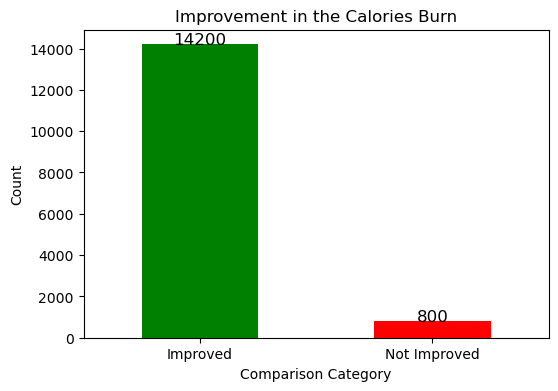

In [195]:

# Count occurrences of "Improved" and "Not Improved"
comparison_counts = df_bpm_new['Comparison'].value_counts()

# Plot the bar chart
plt.figure(figsize=(6, 4))
comparison_counts.plot(kind='bar', color=['green', 'red'])

# Customize labels and title
plt.xlabel("Comparison Category")
plt.ylabel("Count")
plt.title("Improvement in the Calories Burn")
plt.xticks(rotation=0)

# Show values on bars
for index, value in enumerate(comparison_counts):
    plt.text(index, value + 2, str(value), ha='center', fontsize=12)

# Display the chart
plt.show()